In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
def plot_clustermap(
    df,
    log1p=False,
    zscore_projects=False,
    zscore_queries=False,
    hide_project_names=False,
    hide_query_names=False,
    row_cluster=True,
    col_cluster=True,
    row_colors=None,
    trim_query_names=-1,
    trim_project_names=-1,
    color_palette="viridis",
    title="",
):
    """
    Affiche et sauvegarde une heatmap à partir d'un objet AnnData contenant
    les moyennes d'expression (obs = projects, var = queries).

    Paramètres:
      - df: DataFrame contenant les valeurs de mean expression (lignes = queries, colonnes = projects).
      - output_plot: chemin vers le fichier de sortie (png).
      - log1p: booléen, appliquer log10(1+x) aux valeurs.
      - zscore_projects: booléen, effectuer un Z-score par colonne (projects).
      - zscore_queries: booléen, effectuer un Z-score par ligne (queries).
      - hide_project_names: booléen, masquer les noms des projects (colonnes).
      - hide_query_names: booléen, masquer les noms des queries (lignes).
      - trim_query_names: entier, longueur maximale pour tronquer les noms des queries (-1 pour ne pas tronquer).
      - trim_project_names: entier, longueur maximale pour tronquer les noms des projects (-1 pour ne pas tronquer).
      - color_palette: nom de la palette de couleurs (viridis par défaut).
      - subtitle: sous-titre à afficher sous le titre principal.
      - title: titre personnalisé (si vide, utilise le titre par défaut).
    """
    # 3. Tronquer les noms si nécessaire
    if trim_query_names > 0:
        df.index = df.index.str.slice(0, trim_query_names)
    if trim_project_names > 0:
        df.columns = df.columns.str.slice(0, trim_project_names)

    # 4. Application du log1p (log10(1+x)) si demandé
    if log1p:
        df = np.log10(1 + df)

    # 5. Z-score éventuels
    if zscore_projects:
        # Z-score par colonne (projects)
        df = (df - df.mean(axis=0)) / df.std(axis=0)
    if zscore_queries:
        # Z-score par ligne (queries)
        df = df.subtract(df.mean(axis=1), axis=0).divide(df.std(axis=1), axis=0)

    # Construction du titre principal
    if not title:
        title = "Heatmap of mean expressions"
        if zscore_projects and zscore_queries:
            title += " (zscore projets & queries)"
        elif zscore_projects:
            title += " (zscore projets)"
        elif zscore_queries:
            title += " (zscore queries)"

    # Label de la colorbar
    cbar_label = "Mean expression"
    if log1p:
        cbar_label += " (log10(1+x))"

    # 8. Centrer la colormap sur zéro si z-score appliqué
    if zscore_projects or zscore_queries:
        max_abs = max(abs(np.nanmin(df.values)), abs(np.nanmax(df.values)))
        vmin, vmax = -max_abs, max_abs
        cbar_label = "Z-score"
    else:
        vmin, vmax = None, None

    # 9. Affichage de la heatmap
    ax = sns.clustermap(
        df,
        cmap=color_palette,
        vmin=vmin,
        vmax=vmax,
        yticklabels=not hide_query_names,
        xticklabels=not hide_project_names,
        cbar_kws={"label": cbar_label},
        row_cluster=row_cluster,
        col_cluster=col_cluster,
        row_colors=row_colors,
    )
    ax.fig.suptitle(title, fontsize=20)
    # Orientation horizontale des labels des queries (lignes)
    if not hide_query_names:
        ax.ax_heatmap.set_yticklabels(ax.ax_heatmap.get_yticklabels(), rotation=0)

    # Ajustement des marges
    plt.tight_layout()
    # 10. Sauvegarde du plot
    ax.fig.savefig(
        'heatmap.pdf',
        dpi=300,
        bbox_inches='tight'
    )
    plt.show()
    plt.close()

In [33]:
d = '/mnt/raid0/personalized_antigen_discovery_2/bioinfo/main/wf_plot_estimate/_data/estimates/'

In [34]:
neogenes_estimates = pd.read_csv(f'{d}ews_127_neogenes/ews_127_neogenes.CUS-EW_illumina.sparse.tsv', sep='\t')
neoisoforms_estimates = pd.read_csv(f'{d}/Neoexons_only_20260217/Neoexons_only_20260217.CUS-EW_illumina.sparse.tsv', sep='\t')
neogenes_estimates['annotation'] = 'Neogene'
neoisoforms_estimates['annotation'] = 'Neoisoform neoexon'
neoproteins = pd.concat([neogenes_estimates, neoisoforms_estimates])

In [54]:
palette = {
    "Neogene": "#1b365d",
    "Neoisoform neoexon": "#D0E8F8"
}

In [56]:
ann = neoproteins.set_index('Unnamed: 0')['annotation'].map(palette)

In [57]:
df = neoproteins.drop(columns='annotation').set_index('Unnamed: 0').astype(float)

In [74]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42   # <-- ADD THIS before creating the figure
matplotlib.rcParams['ps.fonttype'] = 42  

/home/mariia/miniforge3/envs/analysis/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


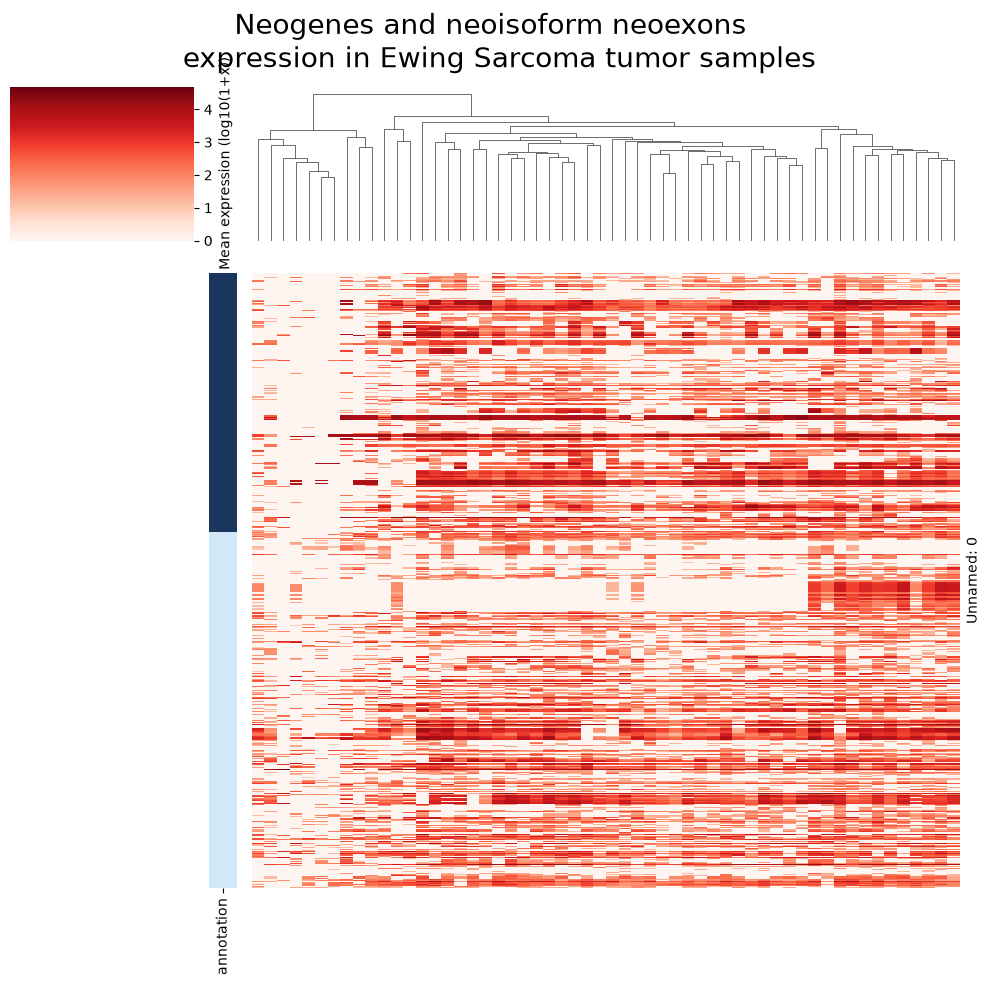

In [90]:

plot_clustermap(
        df,
        hide_query_names=True,
        hide_project_names=True,
        color_palette='Reds',
        log1p=True,
        title='Neogenes and neoisoform neoexons \n expression in Ewing Sarcoma tumor samples',
        row_cluster=False,
        col_cluster=True,
        row_colors=ann.reindex(df.index)
    )

In [84]:
neoproteins['mean_non_zero'] = neoproteins[[col for col in neoproteins.columns if col.startswith('EW')]].replace(0, np.nan).mean(axis=1)
neoproteins['mean_non_zero_log10'] = np.log10(neoproteins['mean_non_zero'])
neoproteins['proportion_non_zero'] = neoproteins[[col for col in neoproteins.columns if col.startswith('EW')]].replace(0, np.nan).count(axis=1) / neoproteins[[col for col in neoproteins.columns if col.startswith('EW')]].shape[1]
neoproteins

,Unnamed: 0,EW-illumina-A103T17,EW-illumina-A103T19,EW-illumina-A103T20,EW-illumina-A103T21,EW-illumina-A103T22,EW-illumina-A103T23,EW-illumina-A103T24,EW-illumina-A103T25,EW-illumina-A103T26,...,EW-illumina-B95T11,EW-illumina-B95T5,EW-illumina-B95T6,EW-illumina-B95T7,EW-illumina-B95T8,EW-illumina-B95T9,annotation,mean_non_zero,proportion_non_zero,mean_non_zero_log10
0,Ew_NG55.1,33.189205,38.574280,0.000000,26.109728,56.459820,0.000000,0.000000,45.045906,0.0,...,31.689613,41.471806,0.000000,89.531140,248.88152,38.168377,Neogene,50.898149,0.767857,1.706702
1,ENST00000671301,0.000000,27.553057,37.962370,0.000000,13.029189,0.000000,0.000000,28.153690,0.0,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,Neogene,37.922220,0.500000,1.578894
2,Ew_NG1.1,86.291930,22.042446,0.000000,0.000000,0.000000,0.000000,0.000000,22.522953,0.0,...,100.350450,29.622717,17.002642,21.066150,0.00000,0.000000,Neogene,83.691856,0.410714,1.922683
3,TCONS_00012458,46.464886,0.000000,0.000000,0.000000,26.058378,0.000000,0.000000,45.045906,0.0,...,126.758450,71.094520,68.010570,36.865765,0.00000,16.357878,Neogene,110.804335,0.500000,2.044557
4,Ew_NG1.4,219.048750,55.106113,0.000000,36.553620,47.773693,0.000000,0.000000,78.830330,0.0,...,232.390500,94.792694,90.680750,84.264600,0.00000,21.810501,Neogene,182.247110,0.696429,2.260661
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1228,FAM19A5.7,637.232700,258.998750,24.404383,164.491290,143.321090,289.719150,300.534730,270.275420,0.0,...,301.051330,41.471806,317.382630,242.260740,150.36590,103.599884,Neoisoform neoexon,321.145156,0.928571,2.506701
1229,FAM19A5.8,292.065000,38.574280,0.000000,127.937670,69.489010,0.000000,0.000000,56.307380,0.0,...,126.758450,23.698174,147.356220,105.330760,77.77547,76.336754,Neoisoform neoexon,138.530677,0.857143,2.141546
1230,FAM19A5.3,0.000000,38.574280,0.000000,13.054864,21.715315,32.191013,30.391153,28.153690,0.0,...,26.408012,0.000000,28.337734,26.332690,0.00000,0.000000,Neoisoform neoexon,31.340782,0.607143,1.496110
1231,FAM19A5.9,0.000000,38.574280,0.000000,13.054864,21.715315,32.191013,30.391153,28.153690,0.0,...,26.408012,0.000000,28.337734,26.332690,0.00000,0.000000,Neoisoform neoexon,31.340782,0.607143,1.496110


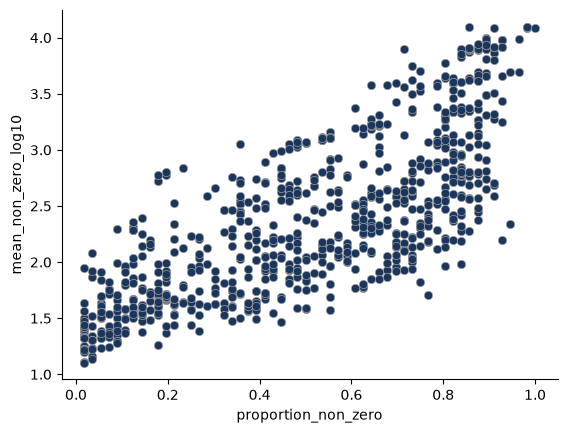

In [98]:
ax =sns.scatterplot(neoproteins[neoproteins['annotation'] == 'Neogene'].set_index('Unnamed: 0'), x='proportion_non_zero', y='mean_non_zero_log10', color="#1b365d", edgecolor="#A0A1A1",)
sns.despine(ax=ax) 
fig = ax.get_figure()
fig.savefig(
		'scatter_ng.pdf',
		dpi=300,
		bbox_inches='tight'
)

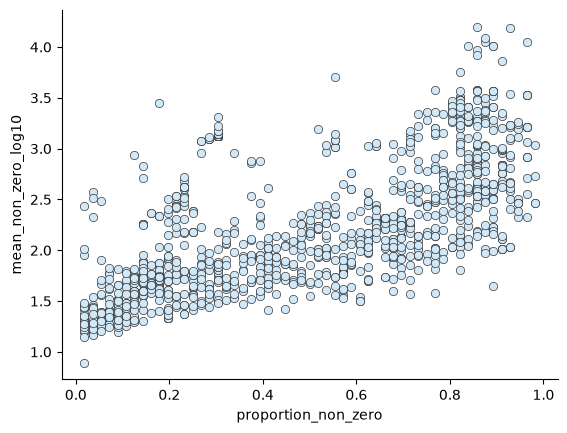

In [99]:
ax =sns.scatterplot(neoproteins[neoproteins['annotation'] == 'Neoisoform neoexon'].set_index('Unnamed: 0'), x='proportion_non_zero', y='mean_non_zero_log10', color="#D0E8F8",edgecolor="#333333")
sns.despine(ax=ax)
fig = ax.get_figure()
fig.savefig(
		'scatter_ni.pdf',
		dpi=300,
		bbox_inches='tight'
)